In [1]:
# Hyper-parameter tunning

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.tree import (DecisionTreeRegressor, DecisionTreeClassifier, plot_tree)
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier, GradientBoostingClassifier)
from sklearn.neighbors import KNeighborsClassifier
import warnings; warnings.filterwarnings("ignore")

churn_df = pd.read_csv('../Data/telecom_churn.csv')

In [3]:
churn_df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
churn_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Parameters: we do not set this, it is learned by the algorithm through the modeling process

In [5]:
# Convert TotalCharges to numeric
churn_df["TotalCharges"] = pd.to_numeric(churn_df["TotalCharges"], errors="coerce")
churn_df = churn_df.dropna(subset=["TotalCharges"])

# Drop customerID as it's not a feature
churn_df = churn_df.drop("customerID", axis=1, errors="ignore")

# Separate target variable
y = churn_df["Churn"].map({"Yes": 1, "No": 0}).astype(int)
X = churn_df.drop("Churn", axis=1)

# One-hot encode all categorical columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [6]:
lr = LogisticRegression()
lr.fit(X_train, y_train)
lr.coef_

#coef_ contains the important information about coefficients on our variables in the model. 
#We do not set this, it is learned by the algorithm through the modeling process

array([[ 2.60280085e-01, -6.05923173e-02,  5.38248705e-03,
         2.92781944e-04, -2.82725267e-03,  1.85196025e-02,
        -2.52933618e-01, -4.75377708e-01,  2.95110141e-01,
         2.71064240e-01,  5.81239834e-01, -1.18743615e-01,
        -1.18743615e-01, -6.11507629e-01, -1.18743615e-01,
        -2.62231692e-01, -1.18743615e-01, -3.80515724e-02,
        -1.18743615e-01, -5.81162430e-01, -1.18743615e-01,
         2.06818656e-01, -1.18743615e-01,  1.79800643e-01,
        -5.06641407e-01, -7.04998646e-01,  3.62566225e-01,
        -6.20408933e-02,  2.27766383e-01,  3.67847177e-03]])

In [7]:
# Create a list of original variable names from the training DataFrame
original_variables = X_train.columns

# Extract the coefficients of the logistic regression estimator
model_coefficients = lr.coef_[0]

# Create a dataframe of the variables and coefficients & print it out
coefficient_df = pd.DataFrame({"Variable" : original_variables, "Coefficient": model_coefficients})
print(coefficient_df)

                                 Variable  Coefficient
0                           SeniorCitizen     0.260280
1                                  tenure    -0.060592
2                          MonthlyCharges     0.005382
3                            TotalCharges     0.000293
4                             gender_Male    -0.002827
5                             Partner_Yes     0.018520
6                          Dependents_Yes    -0.252934
7                        PhoneService_Yes    -0.475378
8          MultipleLines_No phone service     0.295110
9                       MultipleLines_Yes     0.271064
10            InternetService_Fiber optic     0.581240
11                     InternetService_No    -0.118744
12     OnlineSecurity_No internet service    -0.118744
13                     OnlineSecurity_Yes    -0.611508
14       OnlineBackup_No internet service    -0.118744
15                       OnlineBackup_Yes    -0.262232
16   DeviceProtection_No internet service    -0.118744
17        

We have succesfully extracted and reviewed a very important parameter for the Logistic Regression Model. The coefficients of the model allow us to see which variables are having a larger or smaller impact on the outcome. Additionally the sign lets us know if it is a positive or negative relationship.

In [8]:
# Print out the top 3 positive variables
top_three_df = coefficient_df.sort_values(by="Coefficient", axis=0, ascending=False)[0:3]
print(top_three_df)

                          Variable  Coefficient
10     InternetService_Fiber optic     0.581240
26            PaperlessBilling_Yes     0.362566
8   MultipleLines_No phone service     0.295110


In [9]:
tree_r = RandomForestClassifier(max_depth=3, random_state=0)
tree_r.fit(X_train, y_train)

y_pred = tree_r.predict(X_test)

We extract a single tree from our random forest model, visualize it and programmatically extract one of the splits.

This node split on feature TotalCharges, at a value of 220.22500610351562


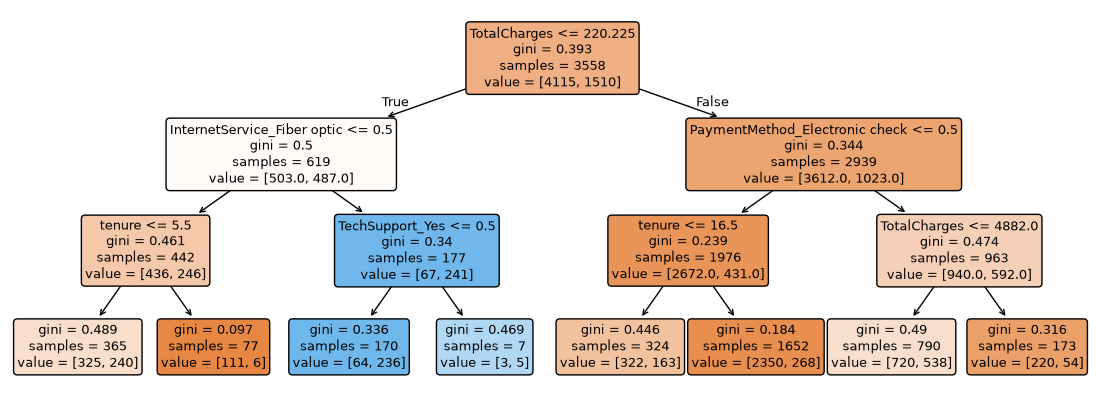

In [10]:
# Extract the 7th (index 6) tree from the random forest
chosen_tree = tree_r.estimators_[6]

fig, ax = plt.subplots(figsize=(14, 5))
plot_tree(chosen_tree, feature_names=X_train.columns, filled=True,
          rounded=True, fontsize=9, ax=ax)

# Extract the parameters and level of the top (index 0) node
split_column = chosen_tree.tree_.feature[0]
split_column_name = X_train.columns[split_column]
split_value = chosen_tree.tree_.threshold[0]

# Print out the feature and level
print("This node split on feature {}, at a value of {}".format(split_column_name, split_value))

In [11]:
# Print out the old estimator, notice which hyperparameter is badly set
print(tree_r)

# Get confusion matrix & accuracy for the old rf_model
print("Confusion Matrix: \n\n {} \n Accuracy Score: \n\n {}".format(
  confusion_matrix(y_test, y_pred),
  accuracy_score(y_test, y_pred))) 

RandomForestClassifier(max_depth=3, random_state=0)
Confusion Matrix: 

 [[975  58]
 [254 120]] 
 Accuracy Score: 

 0.7782515991471215


In [12]:
# Create a new random forest classifier with better hyperparamaters
rf_clf_new = RandomForestClassifier(n_estimators=500)

# Fit this to the data and obtain predictions
rf_new_predictions = rf_clf_new.fit(X_train, y_train).predict(X_test)

# Assess the new model (using new predictions!)
print("Confusion Matrix: \n\n", confusion_matrix(y_test, rf_new_predictions))
print("Accuracy Score: \n\n", accuracy_score(y_test, rf_new_predictions))

Confusion Matrix: 

 [[923 110]
 [184 190]]
Accuracy Score: 

 0.7910447761194029


By changing the n_estimator hyperparameter, we are able to see 2% improvement in the accuracy score of the model.

In [13]:
# Build a knn estimator for each value of n_neighbours
knn_5 = KNeighborsClassifier(n_neighbors=5)
knn_10 = KNeighborsClassifier(n_neighbors=10)
knn_20 = KNeighborsClassifier(n_neighbors=20)

# Fit each to the training data & produce predictions
knn_5_predictions = knn_5.fit(X_train, y_train).predict(X_test)
knn_10_predictions = knn_10.fit(X_train, y_train).predict(X_test)
knn_20_predictions = knn_20.fit(X_train, y_train).predict(X_test)

# Get an accuracy score for each of the models
knn_5_accuracy = accuracy_score(y_test, knn_5_predictions)
knn_10_accuracy = accuracy_score(y_test, knn_10_predictions)
knn_20_accuracy = accuracy_score(y_test, knn_20_predictions)
print("The accuracy of 5, 10, 20 neighbours was: \n{}, \n{}, \n{}".format(knn_5_accuracy, knn_10_accuracy, knn_20_accuracy))

The accuracy of 5, 10, 20 neighbours was: 
0.746268656716418, 
0.7697228144989339, 
0.7775408670931059


In [15]:
# Set the learning rates & results storage
learning_rates = [0.001, 0.01, 0.05, 0.1, 0.2, 0.5]
results_list = []

# Create the for loop to evaluate model predictions for each learning rate
for learning_rate in learning_rates:
    model = GradientBoostingClassifier(learning_rate=learning_rate)
    predictions = model.fit(X_train, y_train).predict(X_test)
    # Save the learning rate and accuracy score
    results_list.append([learning_rate, accuracy_score(y_test, predictions)])

# Gather everything into a DataFrame
results_df = pd.DataFrame(results_list, columns=['learning_rate', 'accuracy'])
print(results_df)

   learning_rate  accuracy
0          0.001  0.734186
1          0.010  0.772566
2          0.050  0.796731
3          0.100  0.795309
4          0.200  0.786780
5          0.500  0.767591


It looks like that after hyper parameter tunning, the learning rate 0.05 has the best accuracy. 

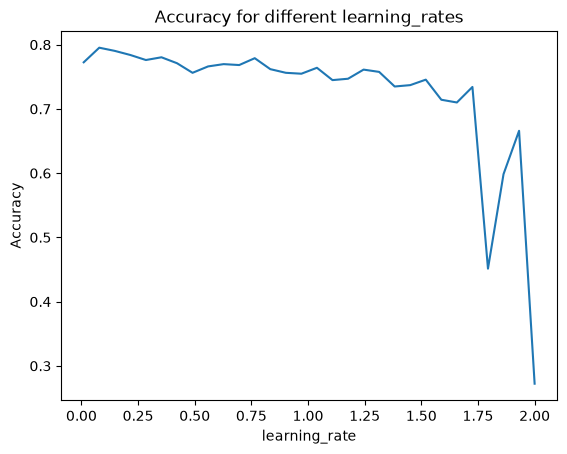

In [16]:
# Set the learning rates & accuracies list
learn_rates = np.linspace(0.01, 2, num=30)
accuracies = []

# Create the for loop
for learn_rate in learn_rates:
  	# Create the model, predictions & save the accuracies as before
    model = GradientBoostingClassifier(learning_rate=learn_rate)
    predictions = model.fit(X_train, y_train).predict(X_test)
    accuracies.append(accuracy_score(y_test, predictions))

# Plot results    
plt.plot(learn_rates, accuracies)
plt.gca().set(xlabel='learning_rate', ylabel='Accuracy', title='Accuracy for different learning_rates')
plt.show()

It looks like the model accuracy is high for learning rates up to 1.6 and then start to drop and rise and drop again.

In [17]:
# Create the function
def gbm_grid_search(learning_rate, max_depth):

	# Create the model
    model = GradientBoostingClassifier(learning_rate=learning_rate, max_depth=max_depth)
    
    # Use the model to make predictions
    predictions = model.fit(X_train, y_train).predict(X_test)
    
    # Return the hyperparameters and score
    return([learning_rate, max_depth, accuracy_score(y_test, predictions)])

In [18]:
# Create the relevant lists
results_list = []
learn_rate_list = [0.01, 0.1, 0.5]
max_depth_list = [2, 4, 6]

# Create the for loop
for learn_rate in learn_rate_list:
    for max_depth in max_depth_list:
        results_list.append(gbm_grid_search(learn_rate,max_depth))

# Print the results
print(results_list)   

[[0.01, 2, 0.7626154939587776], [0.01, 4, 0.7796730632551528], [0.01, 6, 0.7818052594171997], [0.1, 2, 0.7945984363894811], [0.1, 4, 0.7931769722814499], [0.1, 6, 0.7810945273631841], [0.5, 2, 0.7732764747690121], [0.5, 4, 0.7640369580668088], [0.5, 6, 0.7604832977967306]]


In [19]:
results_list = []
learn_rate_list = [0.01, 0.1, 0.5]
max_depth_list = [2,4,6]

# Extend the function input
def gbm_grid_search_extended(learn_rate, max_depth, subsample):

	# Extend the model creation section
    model = GradientBoostingClassifier(learning_rate=learn_rate, max_depth=max_depth, subsample=subsample)
    
    predictions = model.fit(X_train, y_train).predict(X_test)
    
    # Extend the return part
    return([learn_rate, max_depth, subsample, accuracy_score(y_test, predictions)])       

In [20]:
results_list = []

# Create the new list to test
subsample_list = [0.4, 0.6]

for learn_rate in learn_rate_list:
    for max_depth in max_depth_list:
    
    	# Extend the for loop
        for subsample in subsample_list:
        	
            # Extend the results to include the new hyperparameter
            results_list.append(gbm_grid_search_extended(learn_rate, max_depth, subsample))
            
# Print results
print(results_list)            

[[0.01, 2, 0.4, 0.7619047619047619], [0.01, 2, 0.6, 0.7633262260127932], [0.01, 4, 0.4, 0.7796730632551528], [0.01, 4, 0.6, 0.7810945273631841], [0.01, 6, 0.4, 0.7860696517412935], [0.01, 6, 0.6, 0.783226723525231], [0.1, 2, 0.4, 0.7953091684434968], [0.1, 2, 0.6, 0.7889125799573561], [0.1, 4, 0.4, 0.7924662402274343], [0.1, 4, 0.6, 0.7974413646055437], [0.1, 6, 0.4, 0.7810945273631841], [0.1, 6, 0.6, 0.7846481876332623], [0.5, 2, 0.4, 0.7796730632551528], [0.5, 2, 0.6, 0.7853589196872779], [0.5, 4, 0.4, 0.7512437810945274], [0.5, 4, 0.6, 0.7583511016346838], [0.5, 6, 0.4, 0.7320540156361052], [0.5, 6, 0.6, 0.7540867093105899]]
